In [1]:
!pip install -Uqq fastai ddgs

In [2]:
from ddgs import DDGS
from fastcore.all import *
import time

def search_images(keywords, max_images=200):
    return L(DDGS().images(keywords, max_results=max_images)).itemgot('image')

## Download images from the web

In [3]:
from fastai.vision.all import *

path = Path('art_styles')

categories = {
    'renaissance': ['Renaissance painting', 'Italian Renaissance art', 'Renaissance portrait painting'],
    'islamic':     ['Islamic art Middle East', 'Persian miniature painting', 'Islamic geometric art'],
    'asian':       ['Chinese ink painting', 'Japanese ukiyo-e painting', 'Korean traditional painting'],
}

for label, queries in categories.items():
    dest = path/label
    dest.mkdir(exist_ok=True, parents=True)
    # Creates art_styles/renaissance, art_styles/islamic, art_styles/asian

    for q in queries:
        download_images(dest, urls=search_images(q, max_images=60))
        time.sleep(5)

    resize_images(dest, max_size=400, dest=dest)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Remove broken images

In [5]:
import shutil
shutil.rmtree(path/'islamic')

In [6]:
islamic_queries = [
    'Islamic miniature painting',
    'Persian miniature painting',
    'Ottoman miniature painting',
    'Islamic calligraphy art',
    'Islamic geometric pattern art',
]
# Five more specific phrases ("painting", "art", "pattern" help keep results on topic)

for q in islamic_queries:
    print(q)
    print(search_images(q, max_images=5))
    time.sleep(5)
# Prints the first 5 image URLs for each phrase
# Read the URLs: if you see things like "sea-doo", "boat", "cars", that phrase is bad, so remove it from the list

Islamic miniature painting
['https://i.pinimg.com/236x/39/f7/ce/39f7ce4b498302affe1c6576bad14ae5.jpg', 'https://images.museumwnf.org/zoom/objects/epm/sw/21/1/1.jpg', 'https://i.pinimg.com/originals/d0/f6/7d/d0f67d85f22b83e731d67c40ad476bf2.jpg', 'https://c8.alamy.com/comp/GD23XC/fine-arts-islamic-art-persia-miniature-men-at-an-open-air-feat-shiraz-GD23XC.jpg', 'https://i.etsystatic.com/17873164/r/il/5b07e4/4534862119/il_1080xN.4534862119_8e23.jpg']
Persian miniature painting
['https://www.packtoiran.com/media/ckeditor/20201203-043727-8912-140338-0.jpg', 'https://cdn.sanity.io/images/cctd4ker/production/29734ad8e131a598413a15d332b27d12933d3655-2741x3380.jpg?w=2048&q=75&fit=max&auto=format', 'https://i.etsystatic.com/17873164/r/il/e3b712/4315037006/il_fullxfull.4315037006_eb1n.jpg', 'https://i.pinimg.com/736x/74/62/06/7462062577708b051dbd76e89e85f74a.jpg', 'https://i.pinimg.com/originals/1c/c3/6d/1cc36d16156e49906e9dc468486e973e.jpg']
Ottoman miniature painting
['https://i.etsystatic.com

### (Islamic images came broken) Download again

In [7]:
dest = path/'islamic'
dest.mkdir(exist_ok=True, parents=True)

for q in islamic_queries:
    download_images(dest, urls=search_images(q, max_images=40))
    time.sleep(5)
# 5 phrases x 40 = up to 200 images, so we still get ~90+ after cleaning

resize_images(dest, max_size=400, dest=dest)
failed = verify_images(get_image_files(dest))
failed.map(Path.unlink)
# Same resize + remove-broken-files steps as before

print(len(get_image_files(dest)))
# How many Islamic images we have now

167


In [8]:
failed = verify_images(get_image_files(path))

failed.map(Path.unlink)

len(failed)

for label in categories:
    print(label, len(get_image_files(path/label)))

renaissance 94
islamic 167
asian 93


## Build the DataLoaders and look at a batch

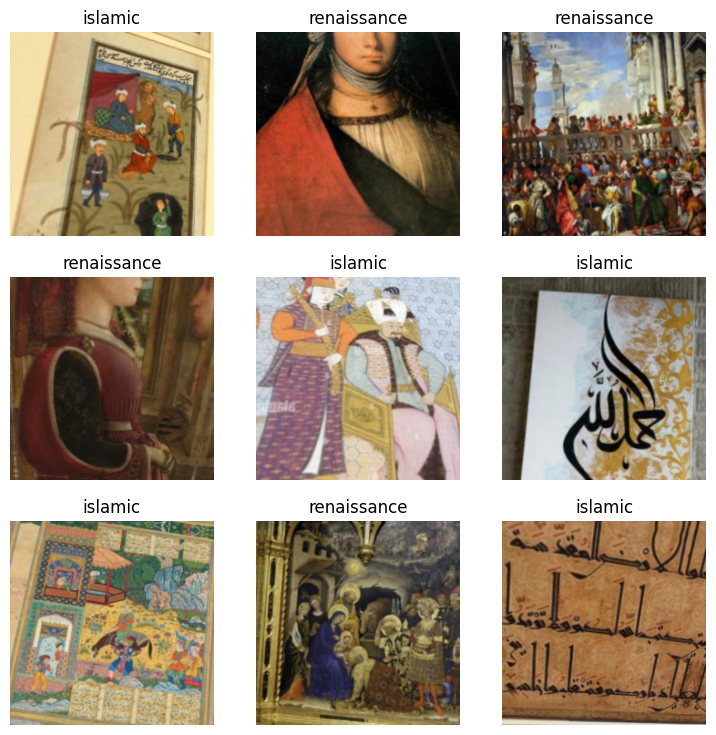

In [13]:
from fastai.vision.all import *

path = Path('art_styles')

dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),

    get_y=parent_label,
    item_tfms=RandomResizedCrop(224, min_scale=0.5),

    batch_tfms=aug_transforms()
).dataloaders(path, bs=32)

dls.show_batch(max_n=9)

## Train the model

In [14]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 113MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,1.430860,0.755506,0.257143,00:03


epoch,train_loss,valid_loss,error_rate,time
0,0.660982,0.574653,0.185714,00:01
1,0.479580,0.430335,0.142857,00:01
2,0.379482,0.410703,0.114286,00:02
3,0.309637,0.403008,0.114286,00:02


## See what the model got wrong

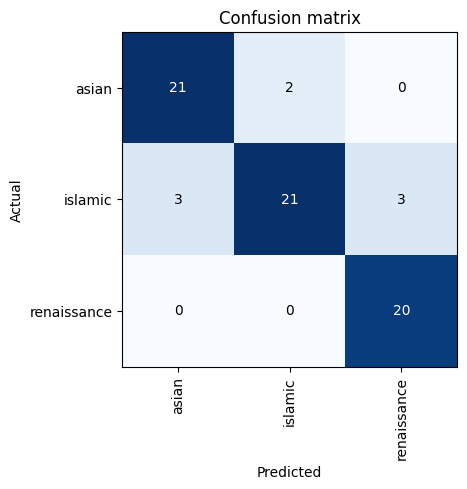

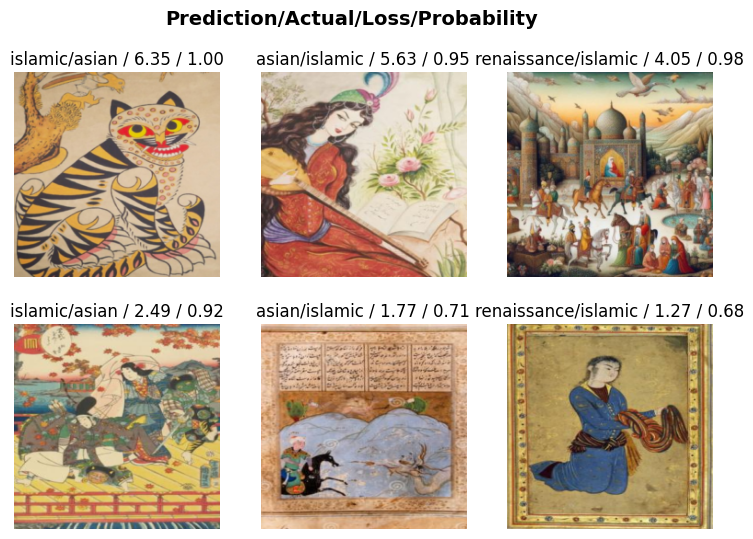

In [15]:
interp = ClassificationInterpretation.from_learner(learn)
# Runs the model on the validation set and stores its predictions + losses

interp.plot_confusion_matrix()
# Grid: rows = real label, columns = predicted label
# The diagonal = correct; anything off the diagonal = a mistake (and which classes got mixed up)

interp.plot_top_losses(6, nrows=2)
# Shows the 6 images the model was most wrong / least sure about
# Title format: predicted / actual / loss / probability

## Try stronger model

In [17]:
learn = vision_learner(dls, resnet34, metrics=error_rate)

learn.fine_tune(6)

epoch,train_loss,valid_loss,error_rate,time
0,1.598943,0.806951,0.257143,00:01


epoch,train_loss,valid_loss,error_rate,time
0,0.776570,0.506306,0.200000,00:02
1,0.575918,0.428614,0.157143,00:02
2,0.418748,0.366179,0.100000,00:02
3,0.337626,0.337103,0.100000,00:02
4,0.294167,0.319520,0.100000,00:02
5,0.267930,0.323946,0.100000,00:02


## Export the model

In [18]:
learn.export('model.pkl')

from google.colab import files
files.download('model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
learn_inf = load_learner('model.pkl')
learn_inf.predict(get_image_files(path/'asian')[0])

/usr/local/lib/python3.13/dist-packages/fastai/learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


('asian', tensor(0), tensor([9.9933e-01, 4.6137e-04, 2.0889e-04]))

## Create a Hugging Face Spavce and app files

In [21]:
import fastai, torch
print(fastai.__version__, torch.__version__)

2.8.12 2.14.1+cu130


## Save the weights and test them

In [22]:
torch.save(learn.model.state_dict(), 'weights.pth')
# Saved as weights.pth, which loads on any Python version

print(learn.dls.vocab)

['asian', 'islamic', 'renaissance']


In [24]:
from torchvision import transforms
from PIL import Image

model = create_vision_model(resnet34, n_out=3, pretrained=False)
model.load_state_dict(torch.load('weights.pth', map_location='cpu'))
model.eval()

tfm = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

img = Image.open(get_image_files(path/'asian')[0]).convert('RGB')
with torch.no_grad():
    probs = torch.softmax(model(tfm(img).unsqueeze(0)), dim=1)[0]
print(probs)

tensor([9.9847e-01, 1.0792e-03, 4.4788e-04])


In [25]:
files.download('weights.pth')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>